# report — visualizing backtest metrics

Reads one run record from `outputs/runs/` (`pf.metrics.load_run`) and plots all per-period details and summary metrics.
Does not read data or rerun the backtest; the record has no daily returns, so NAV is plotted only at the end of each period (when step = H periods are joined end to end, so period-end NAV is exact).

Metric definitions: S is the strategy; baseline keys are given by `backtest.baseline_keys`;
relative metrics er = ret.S − ret.b, dsr = sharpe.S − sharpe.b, dmdd = mdd.S − mdd.b (only dmdd < 0 counts as a win);
p_ret / p_sharpe are the ranks among n_random random portfolios (0–100; only > 50 counts as a win).
The mean / median / quantiles / win / se in the charts are all taken from `metrics` in the record (the output of `evaluate`), not recomputed here;
per-period scatter plots, box plots etc. only show distributions. The last cell checks that every summary key has been marked in a chart.

In [91]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
import numpy as np
import pandas as pd

import pf.backtest
import pf.config
import pf.metrics

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Choose a run record

Change `RUN_FILE` to view another record (file names are in `outputs/runs/`).

In [92]:
RUN_FILE = "20261013_171155_val-mad_1cb7.json"

rec = pf.metrics.load_run(pf.config.RUNS_DIR / RUN_FILE)
cfg = rec.config
H, A, ev = cfg.task.holding_days, cfg.task.periods_per_year, cfg.task.eval
keys = pf.backtest.baseline_keys(ev)   # deterministic baselines, e.g. gspc, ew_pool, ew_sel, mom, nvda
objects = ["S", *keys]
qs = [f"p{round(v * 100, 10):g}" for v in ev.quantiles]   # quantile statistic names, e.g. p10, p90

# Per-period detail; ret.S is period_return. Relative metrics use the same definition as evaluate
per = rec.periods.rename(columns={"period_return": "ret.S"})
for b in keys:
    per[f"er.{b}"] = per["ret.S"] - per[f"ret.{b}"]
    per[f"dsr.{b}"] = per["sharpe.S"] - per[f"sharpe.{b}"]
    per[f"dmdd.{b}"] = per["mdd.S"] - per[f"mdd.{b}"]
cash_only = per["vol.S"] == 0   # all-cash periods: the summaries of sharpe.S, dsr and p_sharpe.S skip them

cmap = plt.get_cmap("tab10")
COLORS = {"S": "black", **{b: cmap(i) for i, b in enumerate(keys)}}

shown: set[str] = set()   # summary keys already marked in a chart; coverage is checked at the end


def stat(key: str) -> float:
    # Summary metrics are fetched only through here, recording which keys have been charted.
    shown.add(key)
    return rec.metrics.get(key, np.nan)


def stat_lines(ax, metric: str, obj: str, stats: list[str], orient: str = "h") -> None:
    # Draw reference lines for summary statistics on ax, with values in the legend.
    style = {"mean": ("C3", "-"), "median": ("C0", "--")}
    line = ax.axhline if orient == "h" else ax.axvline
    for st in stats:
        v = stat(f"{metric}.{obj}.{st}")
        if np.isnan(v):
            continue
        color, ls = style.get(st, ("grey", ":"))
        line(v, color=color, ls=ls, lw=1.2, label=f"{st} = {v:.3g}")


pd.Series({**rec.meta, "start": rec.run.start, "end": rec.run.end, "step": rec.run.step,
           "H": H, "periods": len(per), "baselines": ", ".join(keys)}, name=RUN_FILE).to_frame()

,20261013_171155_val-mad_1cb7.json
time,2026-10-13T17:11:55
git_commit,a16727502f422fa700bd3ef224871890ed21a67c
label,val-mad
note,det
start,2023-01-01
end,2024-12-31
step,39
H,39
periods,12
baselines,"gspc, ew_pool, ew_sel, mom, nvda"


## Summary metrics at a glance

`metrics` laid out as a table of `<metric>.<subject>` × statistic (for reference only; values are the same as those marked in the charts below).

In [93]:
summary = pd.Series(rec.metrics).drop(["n_periods", "n_cash_only"])
split = summary.index.str.rsplit(".", n=1)
summary_table = (
    pd.DataFrame({"key": [s[0] for s in split], "stat": [s[1] for s in split], "value": summary.to_numpy()})
    .pivot(index="key", columns="stat", values="value")
)
stat_order = [c for c in ["mean", "median", *qs, "win", "se"] if c in summary_table.columns]
summary_table = summary_table.reindex(index=list(dict.fromkeys(s[0] for s in split)), columns=stat_order)
summary_table.style.format("{:.4f}", na_rep="")

stat,mean,median,p10,p90,win,se
key,,,,,,
ret.S,0.0621,0.0504,0.0250,0.1024,,
vol.S,0.2256,0.2060,0.1396,0.3207,,
sharpe.S,1.9548,1.3864,0.4732,3.0755,,
mdd.S,0.0671,0.0521,0.0337,0.1142,,
er.gspc,0.0237,0.0139,-0.0104,0.0488,0.7500,0.0106
er.ew_pool,-0.0143,-0.0195,-0.1019,0.0750,0.2500,0.0201
er.ew_sel,0.0007,0.0023,-0.0171,0.0101,0.5833,0.0054
er.mom,-0.1124,0.0031,-0.5687,0.1149,0.5833,0.0816
er.nvda,-0.1718,-0.1869,-0.4934,0.0353,0.3333,0.0595


## 1. Period-end NAV and per-period returns

Top: period-end NAV of S and each baseline (product of period returns, log scale); drawn only when step = H (periods joined end to end).
Bottom: per-period return ret.S (bar width is the holding period); horizontal lines are summary statistics of ret.S, filled dots are index baselines such as ^GSPC over the same period,
white-filled triangles / white-filled squares are the equal-weight baselines ew_pool (whole pool equal weight) / ew_sel (stocks selected by S, equal weight) over the same period, offset left and right within the bar.

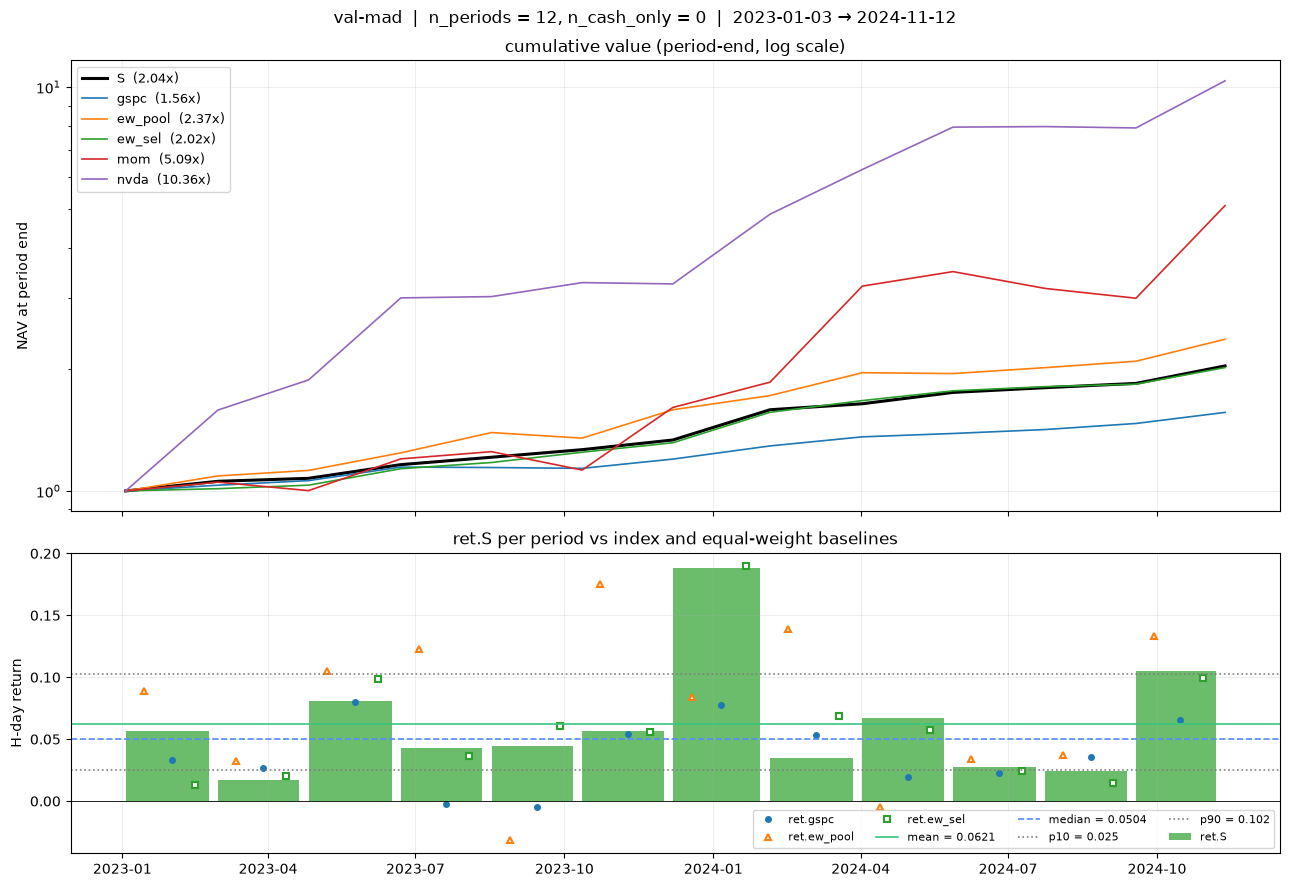

In [94]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
n_periods, n_cash = stat("n_periods"), stat("n_cash_only")
fig.suptitle(f"{rec.meta['label']}  |  n_periods = {n_periods:.0f}, n_cash_only = {n_cash:.0f}  |  "
             f"{per.index[0].date()} → {per['end'].iloc[-1].date()}")

ax = axes[0]
if rec.run.step == H:
    for x in objects:
        nav = (1 + per[f"ret.{x}"]).cumprod()
        nav = pd.concat([pd.Series([1.0], index=per.index[:1]), nav.set_axis(per["end"])])
        ax.plot(nav.index, nav.to_numpy(), color=COLORS[x], lw=2.2 if x == "S" else 1.2,
                label=f"{x}  ({nav.iloc[-1]:.2f}x)")
    ax.set_yscale("log")
    ax.legend(loc="upper left", fontsize=9)
else:
    ax.text(0.5, 0.5, f"step = {rec.run.step} ≠ H = {H}: periods overlap or leave gaps, NAV not chained",
            ha="center", va="center", transform=ax.transAxes)
ax.set_ylabel("NAV at period end")
ax.set_title("cumulative value (period-end, log scale)")
ax.grid(alpha=0.3)

ax = axes[1]
width = (per["end"] - per.index.to_series()).dt.days.to_numpy() * 0.9
ax.bar(per.index, per["ret.S"], width=width, align="edge",
       color=np.where(per["ret.S"] >= 0, "tab:green", "tab:red"), alpha=0.7, label="ret.S")
span = per["end"] - per.index
for b in keys[:len(ev.index_baselines)]:
    ax.plot(per.index + span / 2, per[f"ret.{b}"], "o", ms=4, color=COLORS[b], label=f"ret.{b}")
# Equal-weight baselines use white-filled outlined markers (ew_sel is green like the positive-return bars, so a white fill keeps it visible), offset left and right within the bar so they don't overlap the index's filled dots
for b, marker, pos in [("ew_pool", "^", 0.2), ("ew_sel", "s", 0.75)]:
    if b in keys:
        ax.plot(per.index + span * pos, per[f"ret.{b}"], marker, ms=5, mfc="white", mec=COLORS[b], mew=1.5,
                label=f"ret.{b}")
stat_lines(ax, "ret", "S", ["mean", "median", *qs])
ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("H-day return")
ax.set_title("ret.S per period vs index and equal-weight baselines")
ax.legend(ncol=4, fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()

## 2. Absolute metrics: ret / vol / sharpe / mdd

Left: S's value per period; horizontal lines are summary statistics (sharpe skips all-cash periods, marked with ×).
Right: per-period distributions of S versus each baseline; boxes are quartiles, whiskers are the summary quantiles (p10–p90), triangles are means.

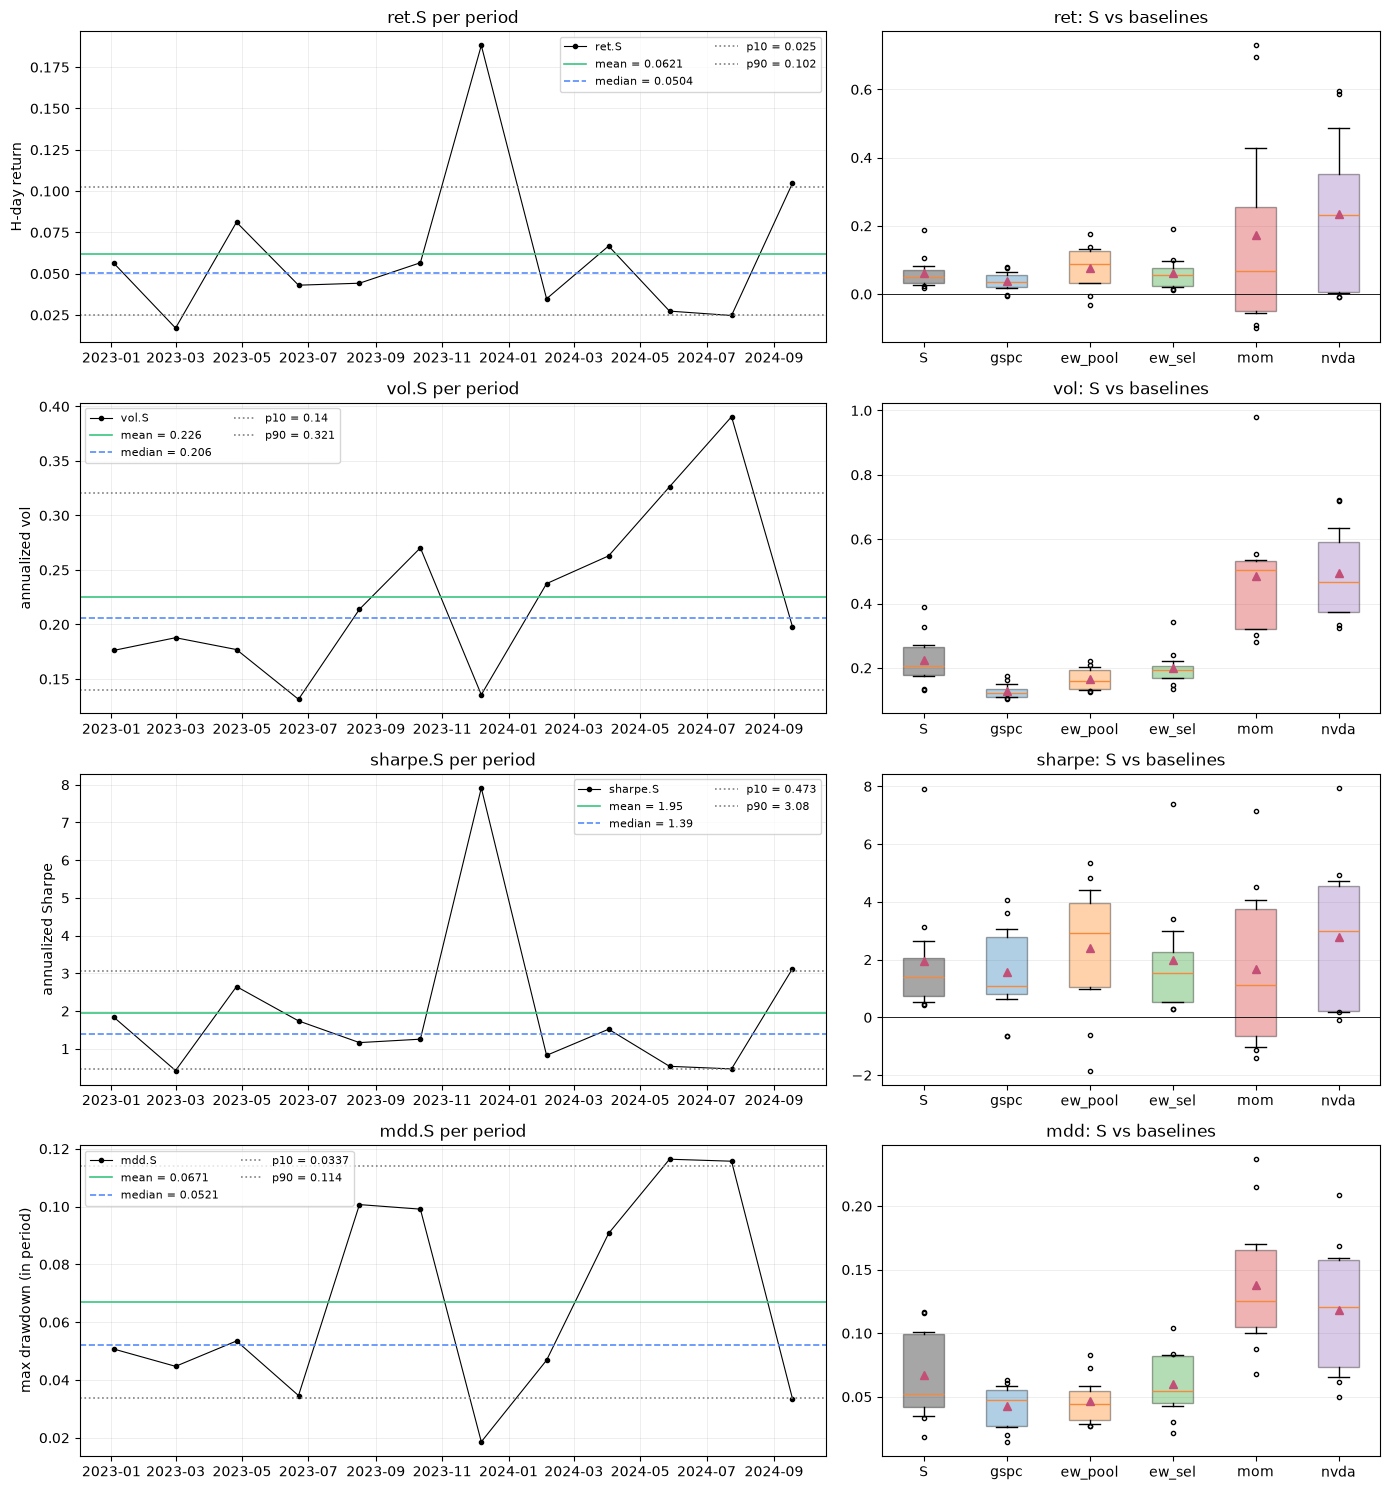

In [95]:
labels = {"ret": "H-day return", "vol": "annualized vol", "sharpe": "annualized Sharpe", "mdd": "max drawdown (in period)"}
fig, axes = plt.subplots(4, 2, figsize=(14, 15), gridspec_kw={"width_ratios": [3, 2]})
for row, metric in zip(axes, ["ret", "vol", "sharpe", "mdd"]):
    ax = row[0]
    s = per[f"{metric}.S"]
    skip = cash_only if metric == "sharpe" else pd.Series(False, index=per.index)
    ax.plot(per.index[~skip], s[~skip], "o-", ms=3, lw=0.8, color="black", label=f"{metric}.S")
    if skip.any():
        ax.plot(per.index[skip], np.zeros(skip.sum()), "x", color="C3", label="cash-only (skipped)")
    stat_lines(ax, metric, "S", ["mean", "median", *qs])
    ax.set_title(f"{metric}.S per period")
    ax.set_ylabel(labels[metric])
    ax.legend(fontsize=8, ncol=2)
    ax.grid(alpha=0.3)

    ax = row[1]
    data = [per[f"{metric}.{x}"][~skip if x == "S" else slice(None)].dropna() for x in objects]
    bp = ax.boxplot(data, tick_labels=objects, whis=(ev.quantiles[0] * 100, ev.quantiles[-1] * 100),
                    showmeans=True, showfliers=True, patch_artist=True, flierprops={"ms": 3})
    for patch, x in zip(bp["boxes"], objects):
        patch.set_facecolor(COLORS[x])
        patch.set_alpha(0.35)
    if metric in ("ret", "sharpe"):
        ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"{metric}: S vs baselines")
    ax.grid(alpha=0.3, axis="y")
fig.tight_layout()

## 3. Relative metrics: er / dsr / dmdd (against each baseline)

Left: one column per baseline; gray dots are per-period values, vertical lines are p10–p90, white squares are medians, red diamonds are mean ± 2·se (when periods overlap se is NaN and no error bar is drawn).
Right: win rate; for er and dsr the share of periods > 0, for dmdd the share of periods < 0 (the strategy's drawdown is shallower). The dashed line is 50%, the shading is 40%–60%.
dsr skips all-cash periods.

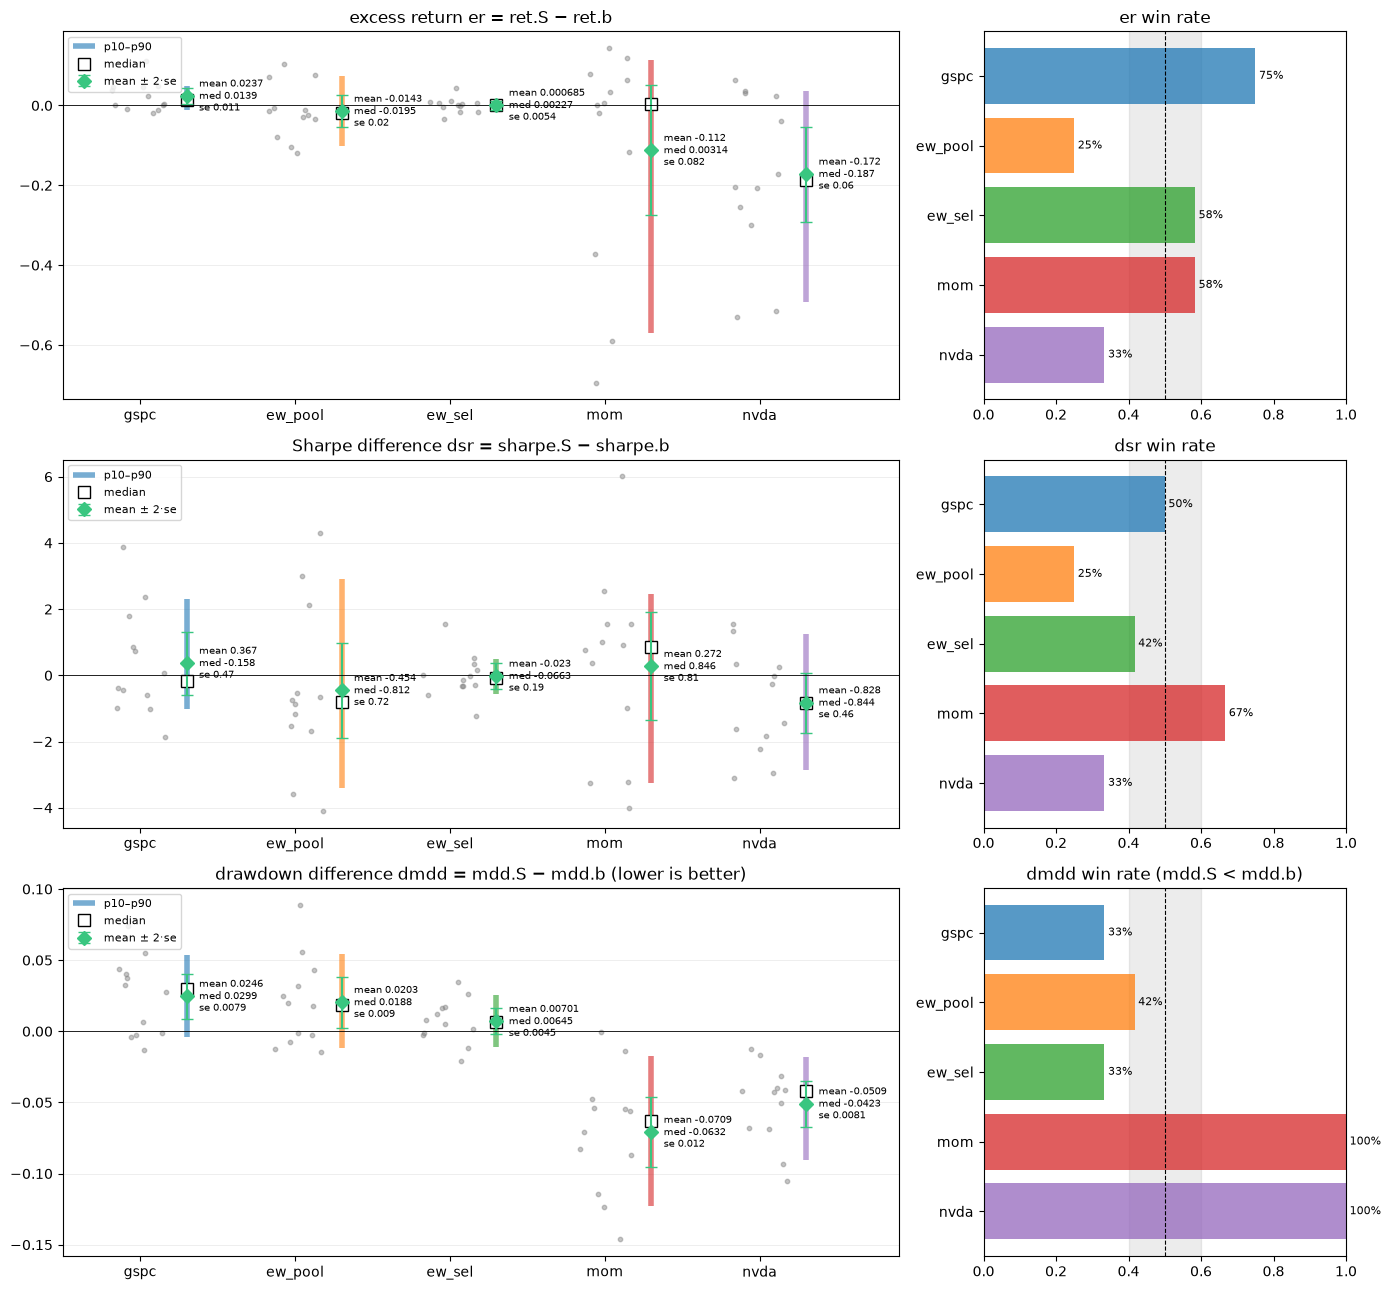

In [96]:
titles = {"er": "excess return er = ret.S − ret.b", "dsr": "Sharpe difference dsr = sharpe.S − sharpe.b",
          "dmdd": "drawdown difference dmdd = mdd.S − mdd.b (lower is better)"}
rng = np.random.default_rng(0)   # used only for horizontal jitter of scatter points
fig, axes = plt.subplots(3, 2, figsize=(14, 13), gridspec_kw={"width_ratios": [3, 1.3]})
for row, metric in zip(axes, ["er", "dsr", "dmdd"]):
    ax = row[0]
    for i, b in enumerate(keys):
        v = per[f"{metric}.{b}"][~cash_only if metric == "dsr" else slice(None)].dropna()
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=10, color="grey", alpha=0.45)
        lo, hi = stat(f"{metric}.{b}.{qs[0]}"), stat(f"{metric}.{b}.{qs[-1]}")
        for q in qs[1:-1]:
            stat(f"{metric}.{b}.{q}")
        ax.vlines(i + 0.3, lo, hi, color=COLORS[b], lw=4, alpha=0.6, label=f"{qs[0]}–{qs[-1]}" if i == 0 else None)
        med, mean, se = (stat(f"{metric}.{b}.{st}") for st in ("median", "mean", "se"))
        ax.plot(i + 0.3, med, "s", ms=8, mfc="white", mec="black", label="median" if i == 0 else None)
        ax.errorbar(i + 0.3, mean, yerr=None if np.isnan(se) else 2 * se, fmt="D", ms=7, color="C3",
                    capsize=4, label="mean ± 2·se" if i == 0 else None)
        ax.annotate(f"mean {mean:.3g}\nmed {med:.3g}\nse {se:.2g}", (i + 0.38, mean), fontsize=7, va="center")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xticks(range(len(keys)), keys)
    ax.set_xlim(-0.5, len(keys) - 0.1)
    ax.set_title(titles[metric])
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(alpha=0.3, axis="y")

    ax = row[1]
    win = pd.Series({b: stat(f"{metric}.{b}.win") for b in keys})
    ax.axvspan(0.4, 0.6, color="grey", alpha=0.15)
    ax.barh(range(len(keys)), win, color=[COLORS[b] for b in keys], alpha=0.75)
    for i, w in enumerate(win):
        ax.text(w + 0.01, i, f"{w:.0%}", va="center", fontsize=8)
    ax.axvline(0.5, color="black", ls="--", lw=0.8)
    ax.set_yticks(range(len(keys)), keys)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_title(f"{metric} win rate" + (" (mdd.S < mdd.b)" if metric == "dmdd" else ""))
fig.tight_layout()

## 4. Time distribution of relative metrics

Each cell is er / dsr / dmdd for one period (column) against one baseline (row); green means the strategy is ahead (the color scale is reversed for dmdd).
Used to see whether excess returns are concentrated in a few periods or a particular time span.

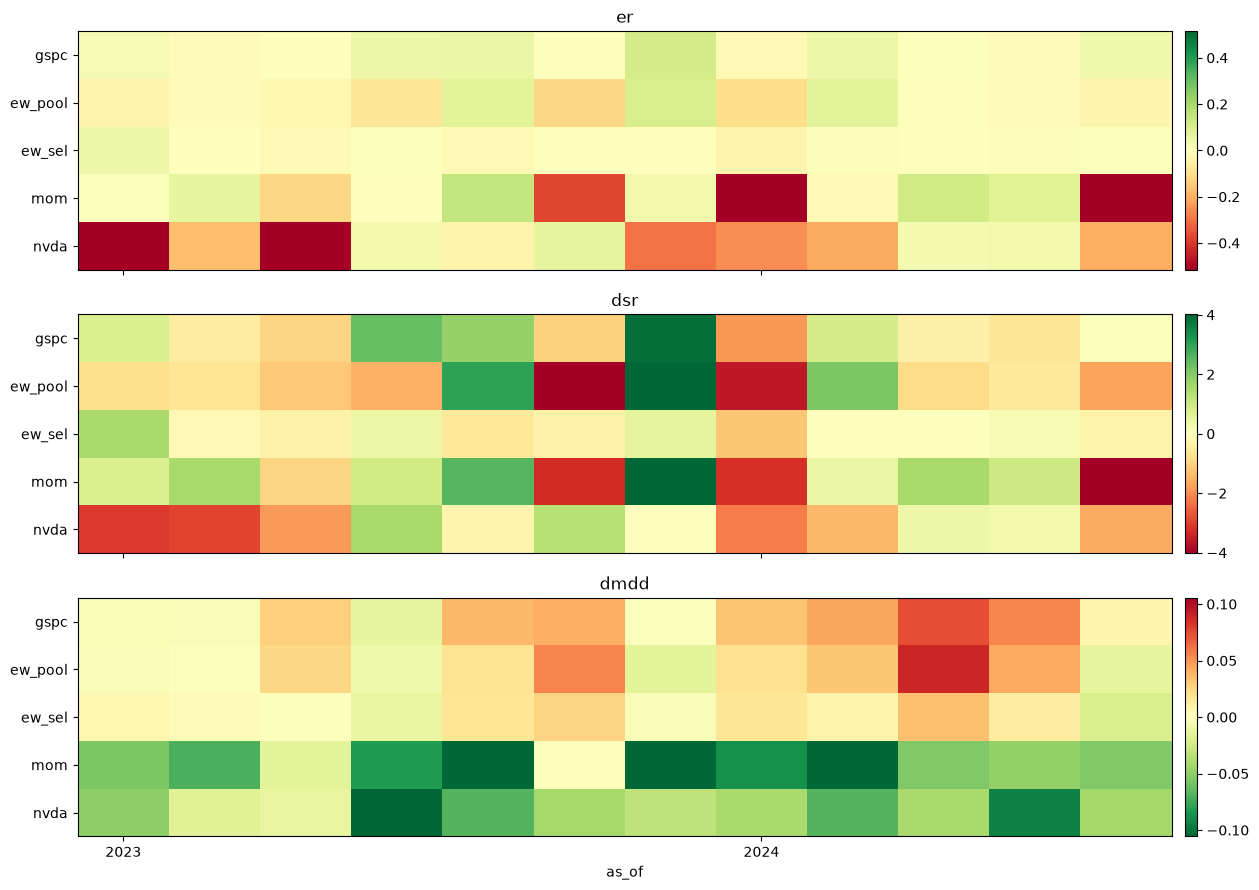

In [97]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, metric in zip(axes, ["er", "dsr", "dmdd"]):
    mat = per[[f"{metric}.{b}" for b in keys]].T.to_numpy(dtype="float64")
    lim = np.nanquantile(np.abs(mat), 0.95)
    im = ax.imshow(mat, aspect="auto", cmap="RdYlGn_r" if metric == "dmdd" else "RdYlGn",
                   vmin=-lim, vmax=lim, interpolation="nearest")
    ax.set_yticks(range(len(keys)), keys)
    ax.set_title(metric)
    fig.colorbar(im, ax=ax, pad=0.01)
years = per.index.year
first = [i for i in range(len(per)) if i == 0 or years[i] != years[i - 1]]
if len(first) > 1 and first[1] < 4:   # when the first period is too close to the next year, label only the year starts to avoid overlapping labels
    first = first[1:]
axes[-1].set_xticks(first, [str(years[i]) for i in first])
axes[-1].set_xlabel("as_of")
fig.tight_layout()

## 5. beta / alpha (against the market M)

Per-period OLS with intercept of $r^S - rf = a + \beta (r^M - rf)$, alpha = a·A (annualized). Horizontal lines are the summary median and quantiles.

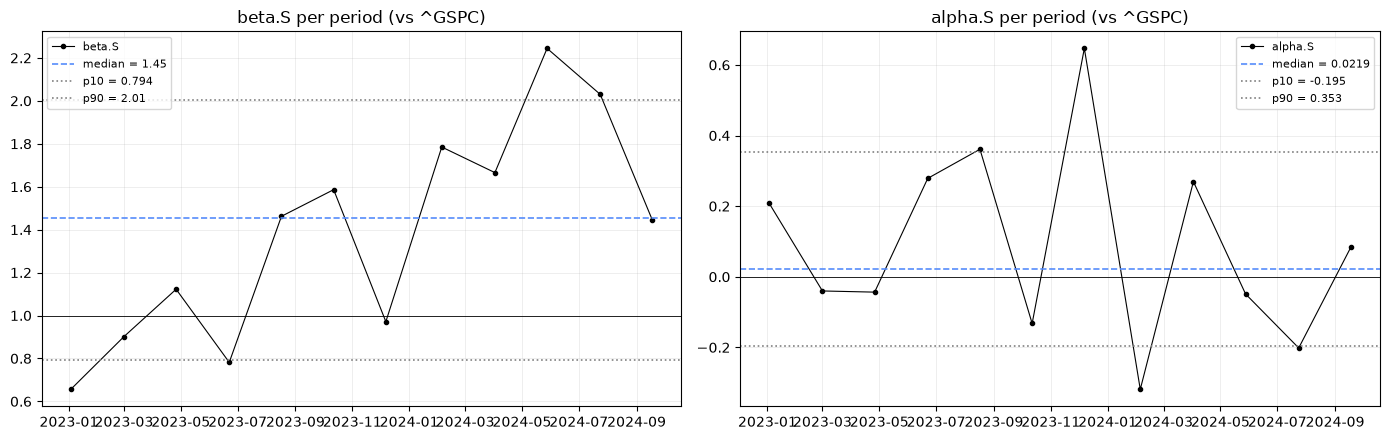

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric, ref in zip(axes, ["beta", "alpha"], [1.0, 0.0]):
    ax.plot(per.index, per[f"{metric}.S"], "o-", ms=3, lw=0.8, color="black", label=f"{metric}.S")
    ax.axhline(ref, color="black", lw=0.6)
    stat_lines(ax, metric, "S", ["median", *qs])
    ax.set_title(f"{metric}.S per period (vs {cfg.data.benchmark})")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.tight_layout()

## 6. Random portfolio ranks: p_ret / p_sharpe

Each period, draw k stocks at random with equal weight from U(t0), n_random portfolios in total; p is the share strictly below S (or ew_sel) × 100.
Top: per-period ranks; bottom: distributions, vertical lines are the summary mean and median. ew_sel picks the same stocks as S, so the difference between the two reflects the contribution of the weighting.

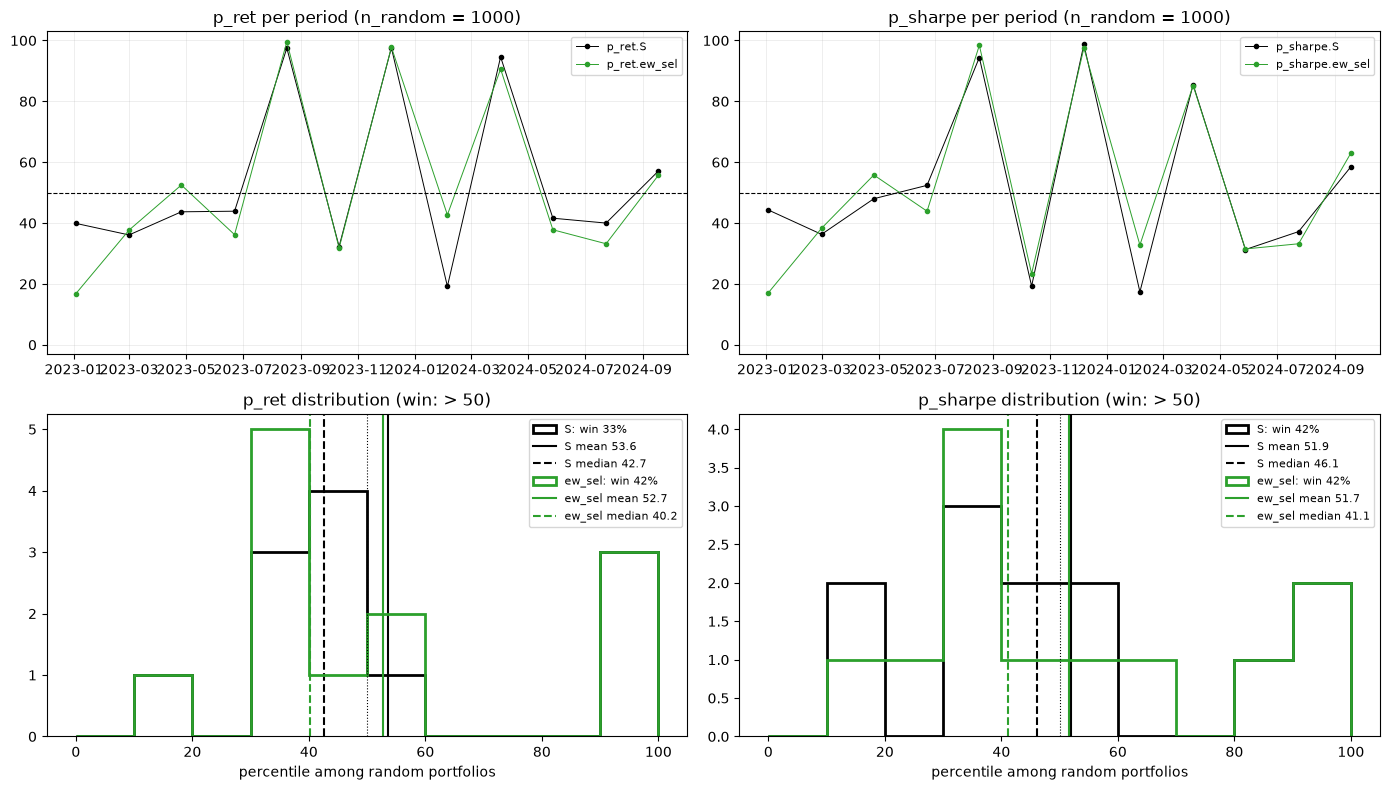

In [99]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
bins = np.linspace(0, 100, 11)
for j, metric in enumerate(["p_ret", "p_sharpe"]):
    ax = axes[0, j]
    for x in ["S", "ew_sel"]:
        v = per[f"{metric}.{x}"][~cash_only if (metric, x) == ("p_sharpe", "S") else slice(None)]
        ax.plot(v.index, v, "o-", ms=3, lw=0.7, color=COLORS[x], label=f"{metric}.{x}")
    ax.axhline(50, color="black", ls="--", lw=0.8)
    ax.set_ylim(-3, 103)
    ax.set_title(f"{metric} per period (n_random = {ev.n_random})")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    ax = axes[1, j]
    for x in ["S", "ew_sel"]:
        v = per[f"{metric}.{x}"][~cash_only if (metric, x) == ("p_sharpe", "S") else slice(None)].dropna()
        mean, med, win = (stat(f"{metric}.{x}.{st}") for st in ("mean", "median", "win"))
        ax.hist(v, bins=bins, color=COLORS[x], histtype="step", lw=2, label=f"{x}: win {win:.0%}")
        ax.axvline(mean, color=COLORS[x], lw=1.5, label=f"{x} mean {mean:.1f}")
        ax.axvline(med, color=COLORS[x], ls="--", lw=1.5, label=f"{x} median {med:.1f}")
    ax.axvline(50, color="black", ls=":", lw=0.8)
    ax.set_xlabel("percentile among random portfolios")
    ax.set_title(f"{metric} distribution (win: > 50)")
    ax.legend(fontsize=8)
fig.tight_layout()

## 7. Holdings: per-period selection and weights

One small chart per period: selected stocks in descending weight, with CASH (when ≥ 0.05%) last; each stock has the same color across periods.
Selected stocks with weight 0 (selected by the stock selection but given 0 by MVO) are also listed, with gray labels. The title shows as_of and the period return ret.S.

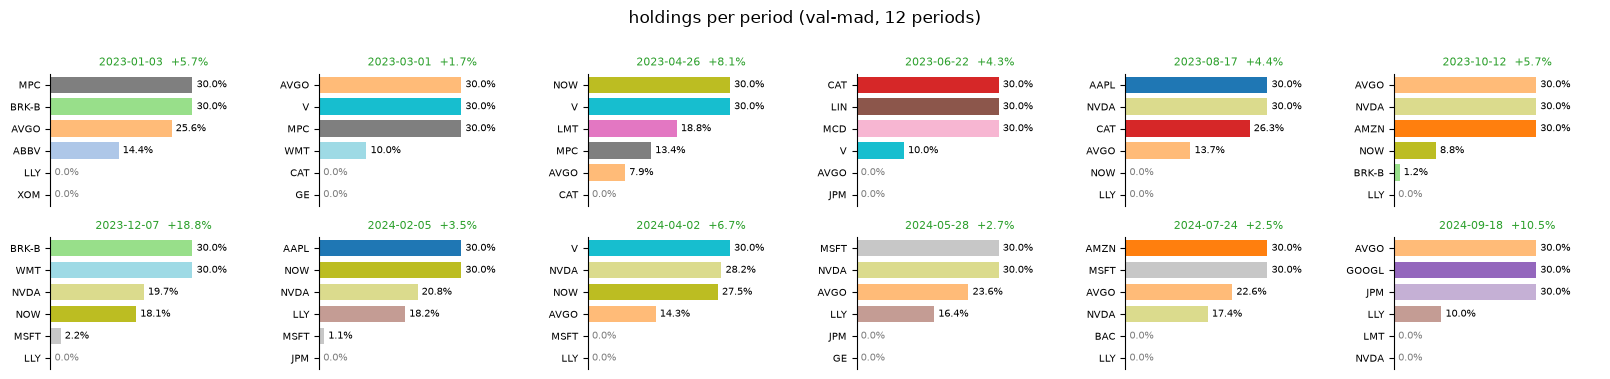

In [100]:
w = rec.weights   # NaN = not selected; 0 = selected but given 0 by MVO
tickers = [c for c in w.columns if c != "CASH"]
# tab20 + tab20b give 40 colors in total, so there are no repeats even with more than 20 stocks
palette = [*plt.get_cmap("tab20").colors, *plt.get_cmap("tab20b").colors]
tcolors = {t: palette[i % len(palette)] for i, t in enumerate(tickers)}
tcolors["CASH"] = (0.75, 0.75, 0.75, 1.0)


def holdings(as_of: pd.Timestamp) -> pd.Series:
    # The period's selected stocks (including weight 0) in descending weight, followed by CASH when ≥ 0.05% (anything smaller is solver residue).
    row = w.loc[as_of]
    sel = row.drop("CASH", errors="ignore").dropna().sort_values(ascending=False, kind="stable")
    cash = row.get("CASH", np.nan)
    return pd.concat([sel, pd.Series({"CASH": cash})]) if cash >= 5e-4 else sel


NCOL = 6
nrow = -(-len(w) // NCOL)
slots = max(len(holdings(d)) for d in w.index)   # same number of rows in each small chart, so bar widths are comparable
xmax = np.nanmax(w.to_numpy()) * 1.45            # leave room on the right for labels
fig, axes = plt.subplots(nrow, NCOL, figsize=(2.7 * NCOL, (0.22 * slots + 0.55) * nrow), squeeze=False)
for ax, as_of in zip(axes.flat, w.index):
    h = holdings(as_of)
    y = np.arange(len(h))
    ax.barh(y, h.to_numpy(), height=0.75, color=[tcolors[t] for t in h.index])
    for yi, v in zip(y, h):
        ax.text(v + xmax * 0.02, yi, f"{v:.1%}", va="center", fontsize=7, color="grey" if v < 5e-4 else "black")
    ax.set_yticks(y, h.index, fontsize=7)
    ax.set_ylim(slots - 0.5, -0.5)
    ax.set_xlim(0, xmax)
    ax.set_xticks([])
    for side in ("top", "right", "bottom"):
        ax.spines[side].set_visible(False)
    r = per.at[as_of, "ret.S"]
    ax.set_title(f"{as_of:%Y-%m-%d}  {r:+.1%}", fontsize=8,
                 color="grey" if np.isnan(r) else ("tab:green" if r >= 0 else "tab:red"))
for ax in axes.flat[len(w):]:
    ax.axis("off")
fig.suptitle(f"holdings per period ({rec.meta['label']}, {len(w)} periods)", y=1.0)
fig.tight_layout()

The same content as a table (copyable): one row per period, holdings in descending weight.

In [101]:
holding_table = pd.DataFrame({
    "end": per["end"].dt.strftime("%Y-%m-%d"),
    "ret.S": per["ret.S"],
    "n_sel": per["n_sel.S"],
    "holdings (weight desc)": [
        "   ".join(f"{t} {v:.1%}" for t, v in holdings(d).drop("CASH", errors="ignore").items()) for d in w.index],
    "CASH": w["CASH"] if "CASH" in w.columns else np.nan,
}, index=w.index)
(holding_table.style
    .format({"ret.S": "{:+.2%}", "n_sel": "{:.0f}", "CASH": "{:.1%}"}, na_rep="")
    .format_index(lambda d: f"{d:%Y-%m-%d}")
    .set_properties(subset=["holdings (weight desc)"], **{"text-align": "left", "font-family": "monospace"}))

,end,ret.S,n_sel,holdings (weight desc),CASH
as_of,,,,,
2023-01-03,2023-03-01,+5.65%,6,MPC 30.0% BRK-B 30.0% AVGO 25.6% ABBV 14.4% LLY 0.0% XOM 0.0%,0.0%
2023-03-01,2023-04-26,+1.71%,6,AVGO 30.0% V 30.0% MPC 30.0% WMT 10.0% CAT 0.0% GE 0.0%,0.0%
2023-04-26,2023-06-22,+8.12%,6,NOW 30.0% V 30.0% LMT 18.8% MPC 13.4% AVGO 7.9% CAT 0.0%,0.0%
2023-06-22,2023-08-17,+4.30%,6,CAT 30.0% LIN 30.0% MCD 30.0% V 10.0% AVGO 0.0% JPM 0.0%,0.0%
2023-08-17,2023-10-12,+4.42%,6,AAPL 30.0% NVDA 30.0% CAT 26.3% AVGO 13.7% NOW 0.0% LLY 0.0%,0.0%
2023-10-12,2023-12-07,+5.66%,6,AVGO 30.0% NVDA 30.0% AMZN 30.0% NOW 8.8% BRK-B 1.2% LLY 0.0%,0.0%
2023-12-07,2024-02-05,+18.81%,6,BRK-B 30.0% WMT 30.0% NVDA 19.7% NOW 18.1% MSFT 2.2% LLY 0.0%,0.0%
2024-02-05,2024-04-02,+3.48%,6,AAPL 30.0% NOW 30.0% NVDA 20.8% LLY 18.2% MSFT 1.1% JPM 0.0%,0.0%
2024-04-02,2024-05-28,+6.67%,6,V 30.0% NVDA 28.2% NOW 27.5% AVGO 14.3% MSFT 0.0% LLY 0.0%,0.0%


Per-period n_sel.S and w_cash.S; horizontal lines are the summary means.

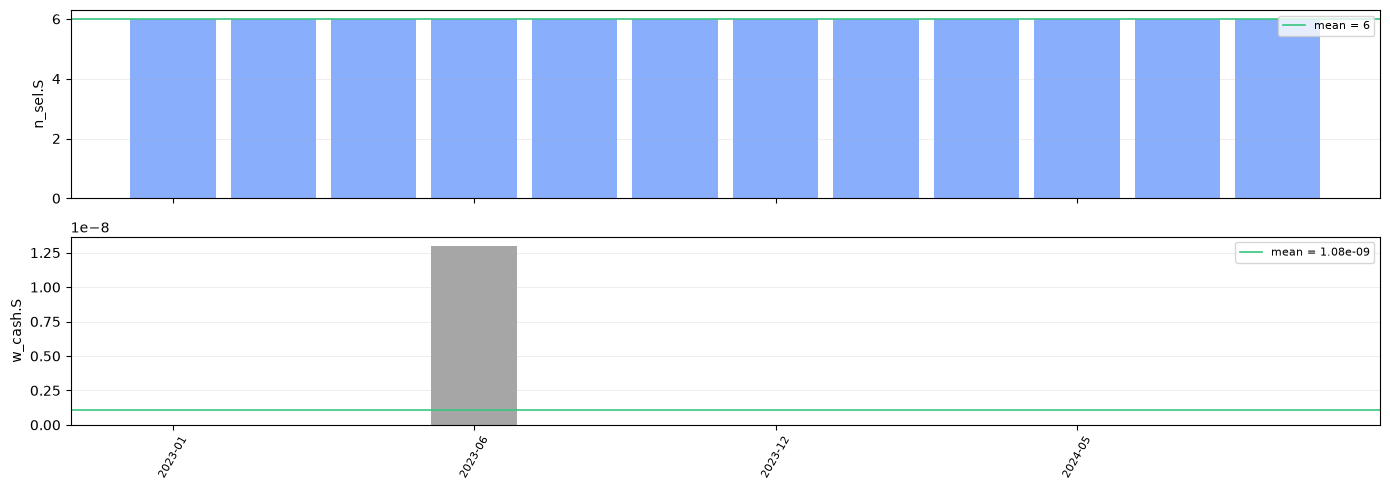

In [102]:
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
x = np.arange(len(per))
for ax, metric in zip(axes, ["n_sel", "w_cash"]):
    ax.bar(x, per[f"{metric}.S"], color="C0" if metric == "n_sel" else "grey", width=0.85, alpha=0.7)
    stat_lines(ax, metric, "S", ["mean"])
    ax.set_ylabel(f"{metric}.S")
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(alpha=0.3, axis="y")
axes[-1].set_xticks(x[::3], [d.strftime("%Y-%m") for d in per.index[::3]], rotation=60, fontsize=8)
fig.tight_layout()

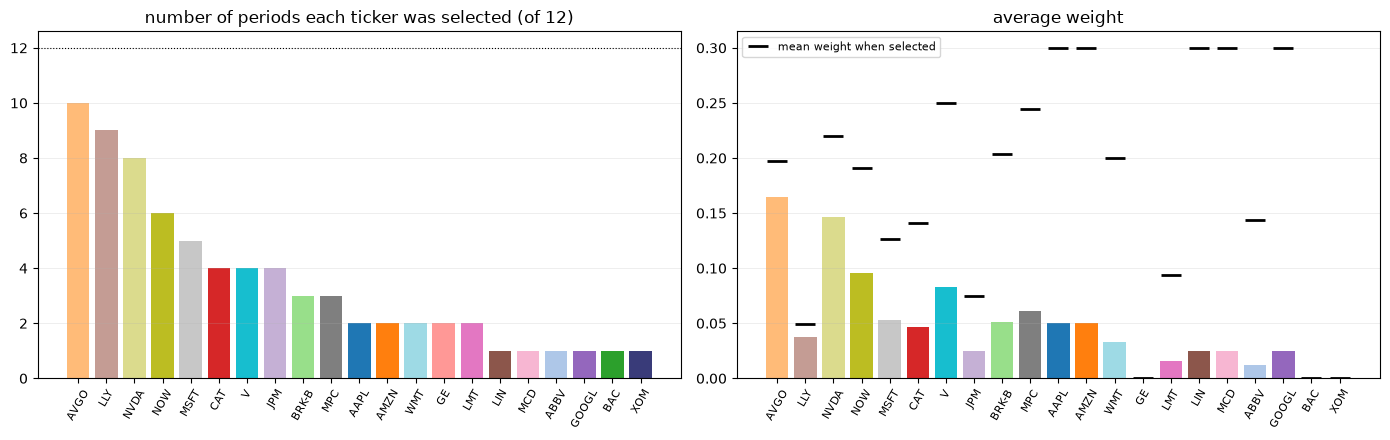

In [103]:
held = rec.weights.drop(columns="CASH", errors="ignore")
usage = pd.DataFrame({
    "periods selected": held.notna().sum(),
    "mean weight when selected": held.mean(),
    "mean weight (all periods)": held.fillna(0.0).mean(),
}).sort_values("periods selected", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=False)
axes[0].bar(usage.index, usage["periods selected"], color=[tcolors[t] for t in usage.index])
axes[0].axhline(len(per), color="black", ls=":", lw=0.8)
axes[0].set_title(f"number of periods each ticker was selected (of {len(per)})")
axes[1].bar(usage.index, usage["mean weight (all periods)"], color=[tcolors[t] for t in usage.index])
axes[1].plot(usage.index, usage["mean weight when selected"], "k_", ms=14, mew=2, label="mean weight when selected")
axes[1].set_title("average weight")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.tick_params(axis="x", rotation=60, labelsize=8)
    ax.grid(alpha=0.3, axis="y")
fig.tight_layout()

## 8. Win rate overview

All win keys in one chart. The 8 main metrics are shown in bold (er and dsr against gspc / ew_pool / mom,
p_ret.S, p_sharpe.S). The shading is 40%–60%.

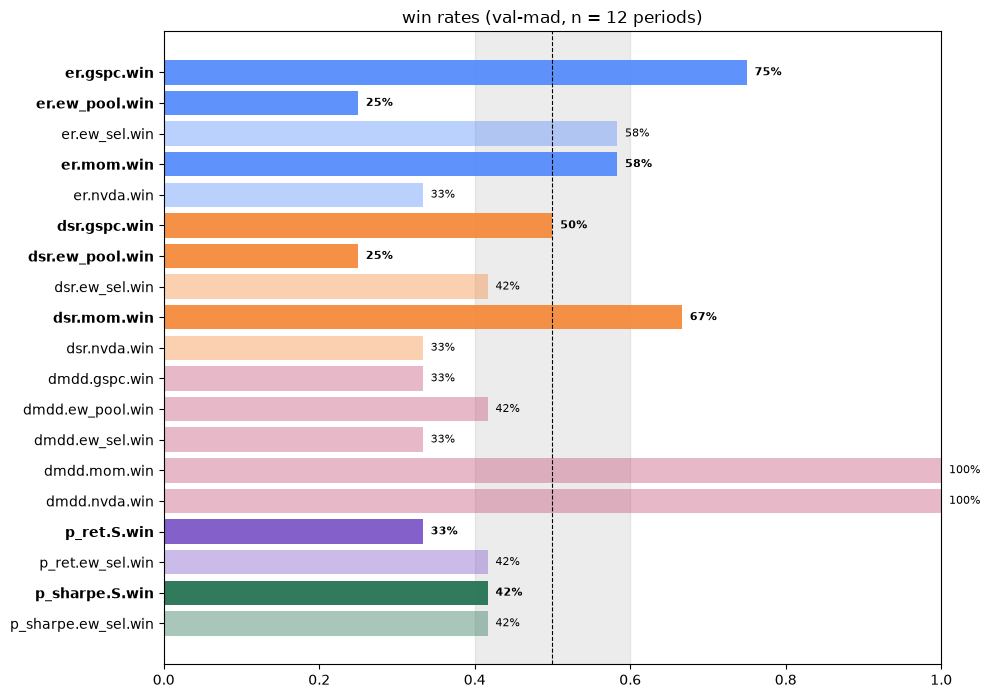

In [104]:
win_keys = [k for k in rec.metrics if k.endswith(".win")]
report = {f"{m_}.{b}.win" for m_ in ("er", "dsr") for b in ("gspc", "ew_pool", "mom")} | {"p_ret.S.win", "p_sharpe.S.win"}
wins = pd.Series({k: stat(k) for k in win_keys})
group_color = {"er": "C0", "dsr": "C1", "dmdd": "C2", "p_ret": "C4", "p_sharpe": "C6"}

fig, ax = plt.subplots(figsize=(10, 0.32 * len(wins) + 1))
y = np.arange(len(wins))
ax.axvspan(0.4, 0.6, color="grey", alpha=0.15)
ax.barh(y, wins, color=[to_rgba(group_color[k.split(".")[0]], 0.95 if k in report else 0.4) for k in wins.index])
for i, (k, v) in enumerate(wins.items()):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=8, fontweight="bold" if k in report else "normal")
ax.axvline(0.5, color="black", ls="--", lw=0.8)
ax.set_yticks(y, wins.index)
for t in ax.get_yticklabels():
    if t.get_text() in report:
        t.set_fontweight("bold")
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_title(f"win rates ({rec.meta['label']}, n = {len(per)} periods)")
fig.tight_layout()

## Check

Every summary key in the record should have been marked in one of the charts above; no output if everything passes.

In [105]:
missing = [k for k in rec.metrics if k not in shown]
assert not missing, f"the following summary keys are not in any chart: {missing}"